In [8]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib
import sklearn

df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [9]:
# See values 
df.shape 



(235795, 56)

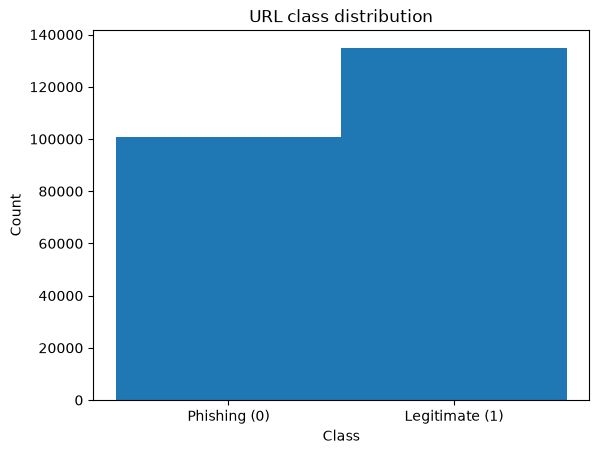

In [12]:
# Plot the distribution of URL classes
plt.hist(df["label"], bins=2)

plt.xlabel("Class")
plt.ylabel("Count")
plt.title("URL class distribution")
plt.xticks([0.25, 0.75], ["Phishing (0)", "Legitimate (1)"])

plt.show()

## Description of the columns

- FILENAME: Identifier of the source file for the example.
- URL: The full website address.
- URLLength: Number of characters in the URL.
- Domain: The domain extracted from the URL.
- DomainLength: Number of characters in the domain.
- IsDomainIP: Indicates whether the domain is an IP address.
- TLD: Top-level domain, such as com, org or no.
- TLDLength: Number of characters in the top-level domain.
- NoOfSubDomain: Number of subdomains.
- NoOfLettersInURL: Number of letters in the URL.
- NoOfDegitsInURL: Number of digits in the URL.
- LetterRatioInURL: Proportion of URL characters that are letters.
- DegitRatioInURL: Proportion of URL characters that are digits.
- NoOfEqualsInURL: Number of equals signs in the URL.
- NoOfQMarkInURL: Number of question marks in the URL.
- NoOfAmpersandInURL: Number of ampersands in the URL.
- label: Target class, where 0 means phishing and 1 means legitimate.

Column names retain the spelling used in the original dataset.

Source: [UCI PhiUSIIL dataset](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset).

In [19]:
# Lager først et nytt enkelt dataset
X = df[["URLLength", "DomainLength", "NoOfDegitsInURL"]]
y = df["label"]

In [17]:
X.head()

,URLLength,DomainLength,NoOfDegitsInURL
0,31,24,0
1,23,16,0
2,29,22,0
3,26,19,0
4,33,26,0


In [ ]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: label, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

# Reserve 20% for the final test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Split the remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

In [25]:
len(X_train), len(X_test)

(141477, 47159)

In [27]:
from sklearn.metrics import accuracy_score

# Find the most common class in the training data
majority_class = y_train.mode().iloc[0]

# Predict that class for every validation example
y_baseline = np.full(len(y_val), majority_class)

print("Baseline accuracy:", accuracy_score(y_val, y_baseline))

Baseline accuracy: 0.5718950783519583


In [32]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Learn scaling from training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Train SGDClassifier
sgd_clf = SGDClassifier(random_state=20)
sgd_clf.fit(X_train_scaled, y_train)

# Evaluate on validation data; reserve test data for the final evaluation
y_val_pred = sgd_clf.predict(X_val_scaled)

print("Validation accuracy:", accuracy_score(y_val, y_val_pred))
print("True and predicted labels for the first 20 validation examples:")
print(list(zip(y_val, y_val_pred))[:20])

Validation accuracy: 0.7927012871350113
True and predicted labels for the first 20 validation examples:
[(1, np.int64(1)), (0, np.int64(1)), (0, np.int64(0)), (1, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(0)), (1, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(0)), (1, np.int64(1))]


[[10805  9384]
 [  392 26578]]


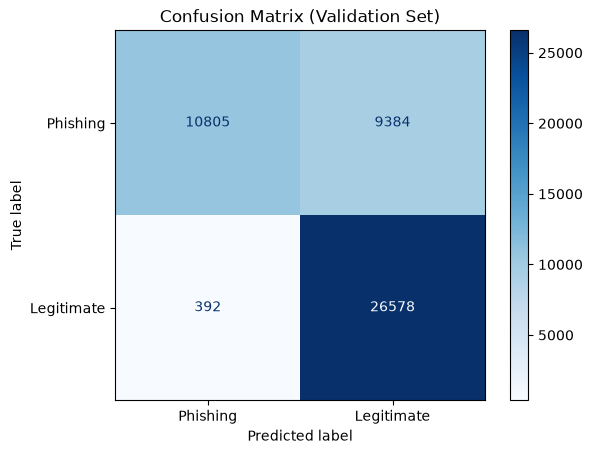

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Compare actual and predicted validation labels
cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues",
)

plt.title("Confusion Matrix (Validation Set)")
plt.show()

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Phishing precision:", precision_score(y_val, y_val_pred, pos_label=0))
print("Phishing recall:", recall_score(y_val, y_val_pred, pos_label=0))
print("Phishing F1:", f1_score(y_val, y_val_pred, pos_label=0))

Phishing precision: 0.9649906224881665
Phishing recall: 0.535192431522116
Phishing F1: 0.6885235455298541


SGDClassifier:
Validation accuracy: 0.7927012871350113
True and predicted labels for the first 20 validation examples:
[(1, np.int64(1)), (0, np.int64(1)), (0, np.int64(0)), (1, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(0)), (1, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(1)), (0, np.int64(1)), (1, np.int64(1)), (1, np.int64(1)), (0, np.int64(0)), (1, np.int64(1))]

[[10805  9384]
 [  392 26578]]
 
Phishing precision: 0.9649906224881665
Phishing recall: 0.535192431522116
Phishing F1: 0.6885235455298541

In [36]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Train on the original, unscaled features
tree_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_clf.fit(X_train, y_train)

# Predict on the same validation set
y_val_pred_tree = tree_clf.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, y_val_pred_tree))
print("Phishing precision:", precision_score(y_val, y_val_pred_tree, pos_label=0))
print("Phishing recall:", recall_score(y_val, y_val_pred_tree, pos_label=0))
print("Phishing F1:", f1_score(y_val, y_val_pred_tree, pos_label=0))

Validation accuracy: 0.8148603659958863
Phishing precision: 0.9288815690971702
Phishing recall: 0.6145921046114221
Phishing F1: 0.7397382776403255


In [37]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Train on the original, unscaled features
rf_clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)
rf_clf.fit(X_train, y_train)

# Predict on the same validation set
y_val_pred_rf = rf_clf.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Phishing precision:", precision_score(y_val, y_val_pred_rf, pos_label=0))
print("Phishing recall:", recall_score(y_val, y_val_pred_rf, pos_label=0))
print("Phishing F1:", f1_score(y_val, y_val_pred_rf, pos_label=0))

Validation accuracy: 0.9591382344833436
Phishing precision: 0.9975479511769835
Phishing recall: 0.9067809203031354
Phishing F1: 0.9500012973197374


In [ ]:
# Function to read URL features from text
from urllib.parse import urlsplit

def extract_url_features(url):
    hostname = urlsplit(url).hostname or ""

    return {
        "URLLength": len(url),
        "DomainLength": len(hostname),
        "NoOfDegitsInURL": sum(character.isdigit() for character in url),
    }

In [39]:
example_url = df["URL"].iloc[0]

print(example_url)
print(extract_url_features(example_url))

print("\nExisting dataset values:")
print(df[["URLLength", "DomainLength", "NoOfDegitsInURL"]].iloc[0])

https://www.southbankmosaics.com
{'URLLength': 32, 'DomainLength': 24, 'NoOfDegitsInURL': 0}

Existing dataset values:
URLLength          31
DomainLength       24
NoOfDegitsInURL     0
Name: 0, dtype: int64


In [40]:
print("Exact URL:", repr(example_url))
print("Length:", len(example_url))
print("Length after stripping whitespace:", len(example_url.strip()))

Exact URL: 'https://www.southbankmosaics.com'
Length: 32
Length after stripping whitespace: 32


In [41]:
X = pd.DataFrame(df["URL"].apply(extract_url_features).tolist())
y = df["label"]

X.head()

,URLLength,DomainLength,NoOfDegitsInURL
0,32,24,0
1,24,16,0
2,30,22,0
3,27,19,0
4,34,26,0


## Retraining with features extracted from raw URLs

We calculate URL length, hostname length and digit count directly from URL text.
This allows training and the website to use the same feature extraction function.
For the first example, our URL length calculation returned 32, while the supplied
dataset value was 31.

We repeat the model comparison using these calculated features and the same
split settings. Model selection uses validation data. The test set remains
reserved for final evaluation.

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Calculate features from raw URLs, preserving row indices
X_extracted = pd.DataFrame(
    [extract_url_features(url) for url in df["URL"]],
    index=df.index,
)
y = df["label"]

# Reserve 20% for the final test
X_train, X_test, y_train, y_test = train_test_split(
    X_extracted,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Overall split: 60% training, 20% validation, 20% testing
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train,
)

# The SGD pipeline learns scaling only from the training data
models_extracted = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "SGDClassifier": make_pipeline(
        StandardScaler(),
        SGDClassifier(random_state=20),
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    ),
}

results = []

for name, model in models_extracted.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "Train accuracy": model.score(X_train, y_train),
        "Validation accuracy": accuracy_score(y_val, predictions),
        "Phishing precision": precision_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Phishing recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
    })

results_extracted = pd.DataFrame(results).set_index("Model")
results_extracted.round(4)

,Train accuracy,Validation accuracy,Phishing precision,Phishing recall,Phishing F1
Model,,,,,
Majority baseline,0.5719,0.5719,0.0000,0.0000,0.0000
SGDClassifier,0.7889,0.7896,0.9645,0.5281,0.6825
Decision Tree,0.8088,0.8082,0.9272,0.5989,0.7278
Random Forest,0.9796,0.9803,0.9955,0.9583,0.9766


In [43]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(exist_ok=True)

joblib.dump(
    models_extracted["Random Forest"],
    model_dir / "random_forest.joblib",
)

['../models/random_forest.joblib']